# 07 — Urutan eksperimen, pemilihan, dan evaluasi

**File:** `07_Evaluasi_dan_Pemilihan.ipynb`

Kita menelusuri runner lengkap serta menghitung ulang metrik delapan kandidat dari prediksi test tersimpan. Pemilihan model direproduksi dari CV, bukan dipilih ulang menggunakan test.

**Input:** comparison_all.csv, selection_frozen.json, prediksi/ringkasan delapan kandidat, protokol. **Hubungan tahap:** 06: recipe/CV/OOF → notebook ini → 08: inferensi model terpilih.

**Cara menjalankan:** pilih kernel `.venv` project, lalu **Restart Kernel and Run All**. Setiap notebook memuat datanya sendiri; tidak memerlukan variabel notebook lain. Source yang tampil dibaca langsung dari fungsi dalam `KODE_ML/03_Kode/` yang di-import, bukan salinan contoh.

**Batas eksekusi:** Run All bawaan membaca hasil utama yang tersimpan dan menjalankan pemeriksaan ringan. Menampilkan definisi fungsi tidak menjalankan training di dalamnya. Hasil lama dan hasil eksekusi pemeriksaan dibedakan pada tiap blok. Training baru hanya melalui gerbang eksplisit di notebook 07, yang default-nya mati.

## Persiapan: pastikan sumber berasal dari KODE_ML

Blok ini mencari folder sumber, menambahkannya ke jalur import, dan memeriksa alamat modul. `sys.dont_write_bytecode` mencegah penulisan cache Python saat belajar. Output alamat membantu mendeteksi bila kita tidak sengaja membuka salinan project lain.

In [1]:
from pathlib import Path
import sys

lokasi = Path.cwd().resolve()
kandidat = [p for induk in [lokasi, *lokasi.parents]
            for p in (induk, induk / "KODE_ML")]
kandidat.append(Path(r"C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML"))
KODE_ML = next((p for p in kandidat if (p / "03_Kode/runtime.py").is_file()), None)
if KODE_ML is None:
    raise FileNotFoundError("Buka notebook dari folder KODE_ML yang lengkap.")
sys.dont_write_bytecode = True
sys.path.insert(0, str(KODE_ML.parent))
sys.path.insert(0, str(KODE_ML))
from IPython.display import display, Markdown
from belajar import tampilkan_sumber, tampilkan_awal
from research import runtime
assert Path(runtime.__file__).resolve().is_relative_to(KODE_ML.resolve())
print("Source aktif:", Path(runtime.__file__).resolve().parent)

Source aktif: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\KODE_ML\03_Kode


### Baca delapan kandidat dan hasil utama

Dua algoritma × A–D menghasilkan delapan kandidat. A/B baseline; C/D tuned. A/C Morgan; B/D Morgan+8. Kolom selected_overall mengikuti AP CV, bukan metrik test tertinggi.

In [2]:
import numpy as np
import pandas as pd
from research import metrics, experiment, validation
from research.results import main_run

run = main_run()
protocol = runtime.read(experiment.PROTOCOL)
freeze = runtime.read(run / "selection_frozen.json")
comparison = pd.read_csv(run / "comparison_all.csv")
print("Urutan kandidat:", experiment.CANDIDATES)
print("Folder hasil:", run)
display(comparison)

Urutan kandidat: ('xgb_A', 'xgb_B', 'xgb_C', 'xgb_D', 'lgbm_A', 'lgbm_B', 'lgbm_C', 'lgbm_D')
Folder hasil: C:\Users\ACER\Documents\Marvel\Skripsi\Project Skripsi\Perfume-MultiLabel-Classifier\.local-tools\campus-transfer-full-20260909\perfume-campus-grouped-v7-m2048-d8\perfume-campus-grouped-v7-m2048-d8\runs\perfume-five-grouped-v7-m2048-d8


,candidate,descriptors,tuned,cv_ap_mean,cv_ap_sd,accuracy,auroc,auprc,specificity,precision,recall,macro_f1_0_5,macro_f1_validation_threshold,selected_for_algorithm,selected_overall
0,xgb_A,0,False,0.249589,0.002441,0.935408,0.809232,0.249043,0.948494,0.228324,0.385921,0.274899,0.275833,False,False
1,xgb_B,8,False,0.277412,0.001425,0.945911,0.822636,0.288125,0.960285,0.284763,0.370450,0.311835,0.309717,False,False
2,xgb_C,0,True,0.267049,0.001463,0.920411,0.825034,0.273029,0.930401,0.197873,0.486615,0.270369,0.293362,False,False
3,xgb_D,8,True,0.296959,0.001128,0.933688,0.838546,0.308827,0.944487,0.234820,0.475521,0.305902,0.327241,True,False
4,lgbm_A,0,False,0.251681,0.003295,0.939379,0.809417,0.252837,0.953052,0.240160,0.360749,0.277184,0.276695,False,False
5,lgbm_B,8,False,0.283211,0.001496,0.948850,0.825813,0.296380,0.963098,0.298800,0.368496,0.320721,0.315920,False,False
6,lgbm_C,0,True,0.269114,0.002343,0.903198,0.827912,0.276461,0.910873,0.173030,0.546478,0.252220,0.300816,False,False
7,lgbm_D,8,True,0.299731,0.001360,0.923660,0.842985,0.310531,0.932611,0.213862,0.515089,0.293156,0.330419,True,True


### Import dan konstanta `metrics.py`

Enam nama metrik dikunci dalam METRICS. Fungsi sklearn yang dipakai ditampilkan agar nama kolom tidak tertukar dengan definisi metrik lain.

In [3]:
tampilkan_awal(metrics)

**Import dan konstanta aktual:** `KODE_ML/03_Kode/metrics.py`. SHA-256: `b476b48133b6b5c9f62f2424f68c72c33cc8ffd2c4a531a64d659878a86f0d67`.

```python
"""Six Suh reporting metrics; actual classifier decisions must be supplied."""
import warnings

import numpy as np
from sklearn.metrics import accuracy_score, average_precision_score, precision_score, recall_score, roc_auc_score

METRICS = ("accuracy", "auroc", "auprc", "specificity", "precision", "recall")


```

### `metrics.binary_metrics` — kode aktual

**File:** `KODE_ML/03_Kode/metrics.py`.

**Input:** satu target biner, skor kontinu, keputusan biner. **Output:** accuracy, AUROC, AP (`auprc`), specificity, precision, recall.

Pemeriksaan memastikan ukuran/nilai valid. TN/FP membentuk specificity. `average_precision_score` adalah Average Precision, bukan luas PR dengan trapezoid. AUROC/specificity dapat None jika hanya ada satu kelas.

Accuracy dihitung per label biner; rata-ratanya **bukan exact-match accuracy** seluruh label satu molekul. Target 0 berarti tidak tercatat di sumber, bukan bukti pasti negatif secara sensoris.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [4]:
tampilkan_sumber(metrics.binary_metrics)

**Source aktual:** `KODE_ML/03_Kode/metrics.py`, baris 10–30. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `b476b48133b6b5c9f62f2424f68c72c33cc8ffd2c4a531a64d659878a86f0d67`.

```python
def binary_metrics(truth, probabilities, predicted):
    y, p, d = np.asarray(truth), np.asarray(probabilities), np.asarray(predicted)
    if y.ndim != 1 or not len(y) or p.shape != y.shape or d.shape != y.shape:
        raise ValueError("Expected equally sized non-empty vectors.")
    if not np.isin(y, [0, 1]).all() or not np.isin(d, [0, 1]).all():
        raise ValueError("Targets and decisions must be binary.")
    if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError("Invalid probabilities.")
    both = np.unique(y).size == 2
    tn = int(np.sum((y == 0) & (d == 0)))
    fp = int(np.sum((y == 0) & (d == 1)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        ap = float(average_precision_score(y, p))
    # sklearn 1.6 returns NaN AUROC for one class; AP still runs in the author's helper.
    return {"accuracy": float(accuracy_score(y, d)),
            "auroc": float(roc_auc_score(y, p)) if both else None,
            "auprc": ap,
            "specificity": tn / (tn + fp) if both else None,
            "precision": float(precision_score(y, d, zero_division=0)),
            "recall": float(recall_score(y, d, zero_division=0))}

```

### `metrics.summarize` — kode aktual

**File:** `KODE_ML/03_Kode/metrics.py`.

**Input:** metrik per label dan daftar label. **Output:** rata-rata macro dan daftar label valid tiap metrik. Setiap label berbobot sama. Cakupan dicatat agar denominator tetap dapat diaudit ketika suatu metrik tidak terdefinisi.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [5]:
tampilkan_sumber(metrics.summarize)

**Source aktual:** `KODE_ML/03_Kode/metrics.py`, baris 33–44. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `b476b48133b6b5c9f62f2424f68c72c33cc8ffd2c4a531a64d659878a86f0d67`.

```python
def summarize(per_label, labels):
    if len(set(labels)) != len(labels) or any(label not in per_label for label in labels):
        raise ValueError("Summary label registry mismatch.")
    scores, coverage = {}, {}
    for metric in METRICS:
        valid = [label for label in labels if per_label[label].get(metric) is not None]
        values = [per_label[label][metric] for label in valid]
        if not all(np.isfinite(values)):
            raise ValueError("Nonfinite metric should be represented explicitly as None.")
        scores[metric] = float(np.mean(values)) if values else None
        coverage[metric] = valid
    return {"metrics": scores, "valid_labels": coverage, "requested_labels": list(labels)}

```

### `metrics.compare` — kode aktual

**File:** `KODE_ML/03_Kode/metrics.py`.

**Input:** dua ringkasan dengan label/cakupan sama. **Output:** kanan dikurangi kiri. Fungsi menolak denominator berbeda. Delta bukan p-value atau bukti signifikansi.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [6]:
tampilkan_sumber(metrics.compare)

**Source aktual:** `KODE_ML/03_Kode/metrics.py`, baris 47–54. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `b476b48133b6b5c9f62f2424f68c72c33cc8ffd2c4a531a64d659878a86f0d67`.

```python
def compare(left, right):
    """Paired label coverage prevents a change of denominator from appearing as a gain."""
    if left["requested_labels"] != right["requested_labels"]:
        raise ValueError("Different summary cohorts.")
    if left["valid_labels"] != right["valid_labels"]:
        raise ValueError("Different valid-label coverage; require an explicitly shared cohort.")
    return {key: right["metrics"][key] - left["metrics"][key]
            if right["metrics"][key] is not None else None for key in METRICS}

```

### Hitung ulang metrik delapan kandidat

Input berasal dari test_predictions.npz. Kode metrik aktual dipanggil lagi, lalu dibandingkan dengan JSON dan CSV. Ini memverifikasi perhitungan dari prediksi tersimpan; belum membuktikan training ulang menghasilkan file identik.

In [7]:
rows, summaries = [], {}
for key in experiment.CANDIDATES:
    with np.load(run / key / "test_predictions.npz", allow_pickle=False) as data:
        y, p, d = data["truth"], data["probabilities"], data["decisions"]
        labels = data["labels"].tolist()
    assert np.array_equal(d, (p >= 0.5).astype(np.int8))
    per_label = {name: metrics.binary_metrics(y[:, j], p[:, j], d[:, j]) for j, name in enumerate(labels)}
    summary = metrics.summarize(per_label, labels)
    diag = validation.prediction_diagnostics(y, d, labels)
    saved = runtime.read(run / key / "test_summary.json")
    assert summary["valid_labels"] == saved["summary"]["valid_labels"]
    for metric, value in summary["metrics"].items():
        assert np.isclose(value, saved["summary"]["metrics"][metric], rtol=0, atol=1e-12)
        assert np.isclose(value, comparison.loc[comparison.candidate.eq(key), metric].iloc[0], rtol=0, atol=1e-12)
    assert np.isclose(diag["macro_f1"], saved["diagnostics"]["macro_f1"], rtol=0, atol=1e-12)
    summaries[key] = summary
    rows.append({"kandidat": key, **summary["metrics"], "macro_f1": diag["macro_f1"]})
display(pd.DataFrame(rows))
print("Metrik 8 kandidat cocok dengan hasil tersimpan, toleransi absolut 1e-12.")

,kandidat,accuracy,auroc,auprc,specificity,precision,recall,macro_f1
0,xgb_A,0.935408,0.809232,0.249043,0.948494,0.228324,0.385921,0.274899
1,xgb_B,0.945911,0.822636,0.288125,0.960285,0.284763,0.370450,0.311835
2,xgb_C,0.920411,0.825034,0.273029,0.930401,0.197873,0.486615,0.270369
3,xgb_D,0.933688,0.838546,0.308827,0.944487,0.234820,0.475521,0.305902
4,lgbm_A,0.939379,0.809417,0.252837,0.953052,0.240160,0.360749,0.277184
5,lgbm_B,0.948850,0.825813,0.296380,0.963098,0.298800,0.368496,0.320721
6,lgbm_C,0.903198,0.827912,0.276461,0.910873,0.173030,0.546478,0.252220
7,lgbm_D,0.923660,0.842985,0.310531,0.932611,0.213862,0.515089,0.293156


Metrik 8 kandidat cocok dengan hasil tersimpan, toleransi absolut 1e-12.


### Visualisasi AP validasi dan test

Mean AP validasi adalah dasar seleksi. AP test adalah pelaporan setelah pilihan dibekukan. Grafik sengaja memisahkan keduanya.

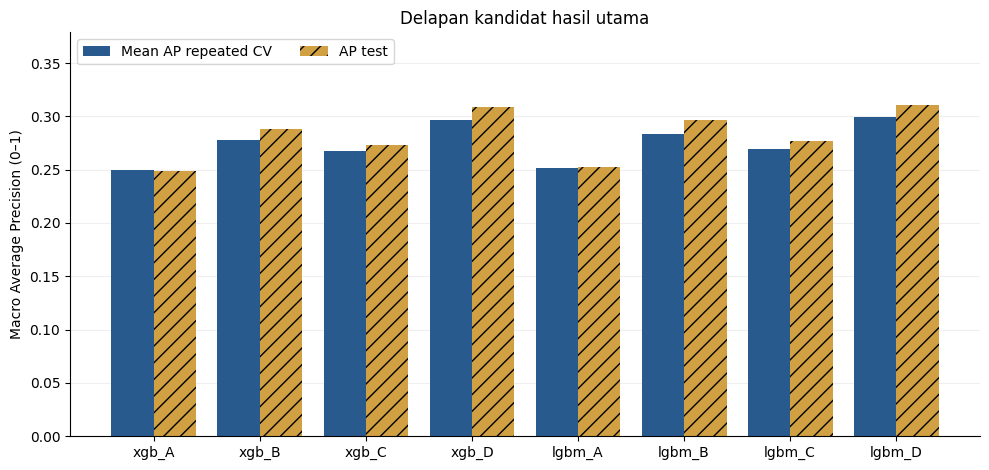

In [8]:
import matplotlib.pyplot as plt

x = np.arange(len(comparison))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - 0.2, comparison.cv_ap_mean, width=0.4, label="Mean AP repeated CV", color="#285A8E")
ax.bar(x + 0.2, comparison.auprc, width=0.4, label="AP test", color="#D0A043", hatch="//")
ax.set_xticks(x, comparison.candidate)
ax.set_ylim(0, max(comparison.cv_ap_mean.max(), comparison.auprc.max()) * 1.22)
ax.set(ylabel="Macro Average Precision (0–1)", title="Delapan kandidat hasil utama")
ax.legend(loc="upper left", ncol=2)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Interpretasi:** LightGBM D dipilih berdasarkan AP CV, tetapi bukan pemenang seluruh metrik. F1/precision pada ambang 0,5 bisa turun dibanding baseline meskipun AP meningkat. Laporan harus menyebut metrik yang naik dan turun.

### Import dan konstanta `experiment.py`

Import menunjukkan urutan dependensi: dataset/fitur → tuning/validasi → final fit → metrik/bundle. CANDIDATES dan TUNED menentukan kombinasi; PROTOCOL menunjuk konfigurasi lokal KODE_ML.

In [9]:
tampilkan_awal(experiment)

**Import dan konstanta aktual:** `KODE_ML/03_Kode/experiment.py`. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
"""Delapan kandidat penelitian utama. Default CLI hanya memeriksa input."""
import argparse
from datetime import datetime, timezone
from pathlib import Path
import platform
import shutil
import warnings
import joblib
import numpy as np
import pandas as pd
import psutil
from . import runtime as core
from .validation import repeated_grouped_cv, prediction_diagnostics
from .metrics import METRICS
from .splits import POLICY
from .dataset import DATASET, verify as verify_dataset
from .features import descriptor_count, features
from .runtime import ROOT, SOURCE_ROOT, digest
from .features import DESCRIPTORS8, N_BITS, EXTRA, verify as verify_descriptors
from .training import fit_final_models
from .metrics import binary_metrics, summarize
OUTPUT = DATASET
from .tuning import tune, event, suggest

warnings.filterwarnings('ignore',message='X does not have valid feature names, but LGBMClassifier was fitted with feature names',category=UserWarning)
RUN_ID='perfume-main-research'
PROTOCOL=SOURCE_ROOT/'config/experiment.json'
ALGORITHMS=('xgb','lgbm')
CANDIDATES=tuple(f'{a}_{c}' for a in ALGORITHMS for c in 'ABCD')
TUNED=tuple(k for k in CANDIDATES if k[-1] in 'CD')

```

### `experiment.verify_files` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** folder dan peta file→hash. **Output:** lolos atau error. Hash mendeteksi file yang berubah; bukan ukuran mutu statistik.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [10]:
tampilkan_sumber(experiment.verify_files)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 32–34. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def verify_files(root, files):
    for name,expected in files.items():
        if digest(Path(root)/name)!=expected: raise ValueError(f'Artifact changed: {name}')

```

### `experiment.preflight` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** dataset/fitur. **Output:** metadata dan protokol tervalidasi. Pemeriksaan meliputi identitas data, environment, algoritma/kondisi, grup/bobot, budget, fitur, recipe awal. Belum ada fitting.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [11]:
tampilkan_sumber(experiment.preflight)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 36–63. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def preflight(dataset, extra=EXTRA):
    meta, _, feature_meta, _, _ = verify_dataset(dataset, extra)
    p = core.read(PROTOCOL)
    if p["id"] != RUN_ID or tuple(p["algorithms"]) != ALGORITHMS or p["conditions"] != list("ABCD"):
        raise ValueError("Wrong active research protocol.")
    if (p["environment"] != core.environment()
            or p["dataset_manifest_sha256"] != digest(Path(dataset)/"dataset_manifest.json")):
        raise ValueError("Dataset/environment mismatch.")
    if p["group_policy"] != POLICY or p["class_imbalance"]["policy"] != core.WEIGHTING_POLICY:
        raise ValueError("Grouped split or weighting mismatch.")
    if p["tuning"]["seconds_total"] != len(TUNED)*p["tuning"]["seconds_per_study"]:
        raise ValueError("Four equal tuning budgets required.")
    if not 5 <= p["tuning"]["heartbeat_seconds"] <= 60:
        raise ValueError("Invalid heartbeat.")
    if p["feature_manifest_sha256"] != digest(Path(extra)/"manifest.json"):
        raise ValueError("Descriptor build differs from the protocol.")
    if (p["features"]["descriptors"] != list(DESCRIPTORS8) or p["features"]["n_bits"] != N_BITS
            or p["features"]["radius"] != 2 or p["features"]["include_chirality"] is not False):
        raise ValueError("Unexpected descriptor definitions.")
    import optuna
    for algorithm in ALGORITHMS:
        recipe = p["initial_recipes"][algorithm]
        with warnings.catch_warnings():
            warnings.simplefilter("error", UserWarning)
            if suggest(optuna.trial.FixedTrial(recipe), algorithm, p) != recipe:
                raise ValueError("Starting recipe is outside the locked search space.")
    meta = dict(meta, feature_spec=feature_meta["feature_spec"])
    return meta, p

```

### `experiment.select_candidates` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** repeated-CV delapan kandidat. **Output:** pilihan keseluruhan/per algoritma serta skor. Penentu adalah mean AP. Tie dalam algoritma mengutamakan A/B/C/D; tie keseluruhan memakai urutan key kode. Tidak ada metrik test dibaca.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [12]:
tampilkan_sumber(experiment.select_candidates)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 66–71. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def select_candidates(robustness):
    scores={k:v['mean_metrics']['auprc'] for k,v in robustness.items()}
    # Exact ties prefer A, B, C, D; model choice uses validation only.
    chosen={a:max((k for k in CANDIDATES if k.startswith(a+'_')),key=lambda k:(scores[k],-'ABCD'.index(k[-1]))) for a in ALGORITHMS}
    overall=max(chosen.values(),key=lambda k:(scores[k],k))
    return overall,chosen,scores

```

### Reproduksi pilihan dari CV tersimpan

Fungsi yang sama dipanggil pada delapan ringkasan lalu dicocokkan dengan pilihan beku. Audit sesudah eksperimen tidak membuat test menjadi "belum pernah dilihat" lagi.

In [13]:
robustness = {key: runtime.read(run / "robustness" / key / "robustness_summary.json") for key in experiment.CANDIDATES}
overall, per_algorithm, scores = experiment.select_candidates(robustness)
assert overall == freeze["overall_selected_from_repeated_grouped_cv"]
assert per_algorithm == freeze["selected_by_algorithm"]
print({"pilihan": overall, "per_algoritma": per_algorithm,
       "test_dipakai_untuk_seleksi_pada_run": freeze["test_used_for_selection"]})

{'pilihan': 'lgbm_D', 'per_algoritma': {'xgb': 'xgb_D', 'lgbm': 'lgbm_D'}, 'test_dipakai_untuk_seleksi_pada_run': False}


### `experiment.evaluate_test` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** run, pilihan beku, kandidat, fitur/target test, label. **Output:** hasil utama 0,5 dan tambahan ambang OOF.

Hasil yang sudah ada diperiksa hash/identitasnya. Pada run baru, model final memprediksi test lalu menyimpan skor/metrik. Ambang tambahan berasal dari OOF train. Karena fungsi bisa menulis file, notebook menghitung metrik secara read-only pada blok sebelumnya.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [14]:
tampilkan_sumber(experiment.evaluate_test)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 73–109. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def evaluate_test(run, frozen, key, x, truth, labels):
    folder=run/key
    models=core.read(folder/'models.json')
    verify_files(folder,{v['file']:v['sha256'] for v in models.values()})
    primary=folder/'test_summary.json'
    if primary.exists():
        result=core.read(primary)
        if result['selection_sha256']!=digest(frozen): raise ValueError('Selection changed.')
        verify_files(folder,result['artifact_sha256'])
        with np.load(folder/'test_predictions.npz',allow_pickle=False) as z:
            prob=z['probabilities']
            if not np.array_equal(z['truth'],truth) or z['labels'].tolist()!=labels:
                raise ValueError('Saved test cohort differs.')
    else:
        prob=np.column_stack([joblib.load(folder/models[name]['file']).predict_proba(x)[:,1] for name in labels]).astype(np.float32)
        decisions=(prob>=.5).astype(np.int8)
        per_label={name:binary_metrics(truth[:,j],prob[:,j],decisions[:,j]) for j,name in enumerate(labels)}
        core.save_npz(folder/'test_predictions.npz',probabilities=prob,decisions=decisions,truth=truth,labels=np.asarray(labels))
        core.write(folder/'test_per_label.json',per_label)
        result={'role':'exploratory research, fixed threshold 0.5','summary':summarize(per_label,labels),'diagnostics':prediction_diagnostics(truth,decisions,labels),'selection_sha256':digest(frozen),'artifact_sha256':{n:digest(folder/n) for n in ('test_predictions.npz','test_per_label.json')}}
        core.write(primary,result)
    thresholds_path=run/'robustness'/key/'thresholds.json'
    secondary=folder/'test_summary_validation_thresholds.json'
    if secondary.exists():
        extra=core.read(secondary)
        if extra['selection_sha256']!=digest(frozen) or extra['threshold_source_sha256']!=digest(thresholds_path): raise ValueError('Threshold source changed.')
        verify_files(folder,extra['artifact_sha256'])
    else:
        threshold_info=core.read(thresholds_path)
        thresholds=np.asarray([threshold_info['labels'][n]['threshold'] for n in labels])
        decisions=(prob>=thresholds[None,:]).astype(np.int8)
        per_label={name:binary_metrics(truth[:,j],prob[:,j],decisions[:,j]) for j,name in enumerate(labels)}
        core.save_npz(folder/'test_predictions_validation_thresholds.npz',probabilities=prob,decisions=decisions,truth=truth,labels=np.asarray(labels),thresholds=thresholds)
        core.write(folder/'test_per_label_validation_thresholds.json',per_label)
        extra={'role':'secondary; thresholds chosen using training OOF only','summary':summarize(per_label,labels),'diagnostics':prediction_diagnostics(truth,decisions,labels),'selection_sha256':digest(frozen),'threshold_source_sha256':digest(thresholds_path),'artifact_sha256':{n:digest(folder/n) for n in ('test_predictions_validation_thresholds.npz','test_per_label_validation_thresholds.json')}}
        core.write(secondary,extra)
    return result,extra

```

### `experiment.paired_cv` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** run/protokol. **Output:** B−A dan D−C per seed. Hash folds antar-kandidat diperiksa sama; delta dihitung pada seed berpasangan. Mean/SD deskriptif, bukan p-value dari pengamatan independen.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [15]:
tampilkan_sumber(experiment.paired_cv)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 111–137. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def paired_cv(run, protocol):
    """Describe paired differences; repeated seeds are not independent experiments."""
    rows = []
    for seed in protocol["robustness"]["seeds"]:
        paths = [run/"robustness"/key/f"seed_{seed}"/"folds.json" for key in CANDIDATES]
        if len({digest(path) for path in paths}) != 1:
            raise ValueError("Candidates used different validation folds.")
    for algorithm in ALGORITHMS:
        for left, right, meaning in (("A", "B", "eight_descriptors_at_fixed_2048_baseline"),
                                      ("C", "D", "eight_descriptors_at_fixed_2048_equal_tuning_budget")):
            a, b = f"{algorithm}_{left}", f"{algorithm}_{right}"
            va = core.read(run/"robustness"/a/"robustness_summary.json")
            vb = core.read(run/"robustness"/b/"robustness_summary.json")
            deltas = [vb["per_seed"][str(s)]["metrics"]["auprc"]
                      - va["per_seed"][str(s)]["metrics"]["auprc"]
                      for s in protocol["robustness"]["seeds"]]
            rows.append({"algorithm": algorithm, "contrast": f"{right}-{left}",
                         "interpretation": meaning, "seeds": protocol["robustness"]["seeds"],
                         "delta_per_seed": deltas, "mean_delta": float(np.mean(deltas)),
                         "sd_delta": float(np.std(deltas, ddof=1)),
                         "added_features_wins": sum(d > 0 for d in deltas),
                         "morgan_only_wins": sum(d < 0 for d in deltas),
                         "ties": sum(d == 0 for d in deltas)})
    result = {"contrasts": rows, "identical_paired_folds": True,
              "caveat": "Descriptive repeated-CV differences, not independent samples, p-values or equivalence tests."}
    core.write(run/"paired_descriptor_cv.json", result)
    return result

```

### `experiment.summaries` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** run, metadata, protokol, pilihan beku. **Output:** tabel kandidat/delta, bundle inferensi, laporan JSON/Markdown.

Blok awal menggabungkan CV/test. Blok tengah membentuk kontras fitur dan tuning. Blok akhir menyimpan urutan fitur/label, model, ambang, environment untuk inferensi. B−A menguji fitur pada baseline tetap; D−C mencakup recipe yang dituning terpisah.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [16]:
tampilkan_sumber(experiment.summaries)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 140–219. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def summaries(run, meta, protocol, freeze):
    rows = []
    for key in CANDIDATES:
        rob = core.read(run/"robustness"/key/"robustness_summary.json")
        test = core.read(run/key/"test_summary.json")
        extra = core.read(run/key/"test_summary_validation_thresholds.json")
        rows.append({"candidate": key, "descriptors": descriptor_count(key),
                     "tuned": key in TUNED, "cv_ap_mean": rob["mean_metrics"]["auprc"],
                     "cv_ap_sd": rob["std_metrics"]["auprc"], **test["summary"]["metrics"],
                     "macro_f1_0_5": test["diagnostics"]["macro_f1"],
                     "macro_f1_validation_threshold": extra["diagnostics"]["macro_f1"],
                     "selected_for_algorithm": key in freeze["selected_by_algorithm"].values(),
                     "selected_overall": key == freeze["overall_selected_from_repeated_grouped_cv"]})
    pd.DataFrame(rows).to_csv(run/"comparison_all.csv", index=False)
    paired = core.read(run/"paired_descriptor_cv.json")
    deltas = []
    label_rows = []
    for algorithm in ALGORITHMS:
        for left, right, meaning in (("A","B","eight_descriptors_fixed_2048_baseline"),
                                     ("C","D","eight_descriptors_fixed_2048_equal_tuning_budget"),
                                     ("A","C","tuning_morgan_2048"),
                                     ("B","D","tuning_morgan_2048_plus_eight")):
            a, b = f"{algorithm}_{left}", f"{algorithm}_{right}"
            va = next(r for r in rows if r["candidate"] == a)
            vb = next(r for r in rows if r["candidate"] == b)
            deltas.append({"algorithm": algorithm, "contrast": f"{right}-{left}", "meaning": meaning,
                           **{f"delta_{m}": vb[m]-va[m] for m in
                              ("cv_ap_mean", *METRICS, "macro_f1_0_5", "macro_f1_validation_threshold")}})
            if (left,right) in (("A","B"),("C","D")):
                ta, tb = (core.read(run/k/"test_per_label.json") for k in (a,b))
                for label in meta["labels"]:
                    label_rows.append({"algorithm":algorithm, "contrast":f"{right}-{left}",
                                       "label":label, "test_ap_morgan":ta[label]["auprc"],
                                       "test_ap_8":tb[label]["auprc"],
                                       "test_ap_delta":tb[label]["auprc"]-ta[label]["auprc"]})
    pd.DataFrame(deltas).to_csv(run/"descriptor_deltas.csv", index=False)
    pd.DataFrame(label_rows).to_csv(run/"descriptor_deltas_per_label_test.csv", index=False)
    overall = freeze["overall_selected_from_repeated_grouped_cv"]
    count = descriptor_count(overall)
    spec = dict(meta["feature_spec"])
    spec.update(descriptors=list(DESCRIPTORS8[:count]), use_descriptors=bool(count),
                dimensions={"input":meta["feature_spec"]["n_bits"]+count},
                dtype="float32", fragment_policy="single")
    feature_names = [f"morgan_{i:04d}" for i in range(spec["n_bits"])] + list(DESCRIPTORS8[:count])
    core.write(run/"inference_bundle.json", {
        "protocol":RUN_ID, "selected_candidate":overall, "algorithm":overall.split("_")[0],
        "models_directory":overall, "models":core.read(run/overall/"models.json"),
        "feature_spec":spec, "feature_names":feature_names, "use_descriptors":bool(count),
        "labels":meta["labels"], "primary_threshold":0.5,
        "secondary_thresholds_path":f"robustness/{overall}/thresholds.json",
        "environment":core.environment(), "selection_sha256":digest(run/"selection_frozen.json"),
        "score_interpretation":"Uncalibrated score, not intensity or mixture composition.",
        "release_policy":"Research only; ONNX and Android remain deferred.",
        "prediction_command":"python -m research.inference --run NEW_RUN_DIRECTORY --smiles SMILES"})
    lines = ["# Hasil penelitian: Morgan 2048 dengan/tanpa delapan deskriptor", "",
             f"Pemenang berdasarkan mean macro AP validasi: **{overall}** ({count} deskriptor).", "",
             protocol["confirmatory_status"], "",
             "| Kandidat | Deskriptor | CV AP | SD | Test AP | AUROC | Macro F1 (0,5) |",
             "|---|---:|---:|---:|---:|---:|---:|"]
    for r in rows:
        lines.append(f"| {r['candidate']} | {r['descriptors']} | {r['cv_ap_mean']:.6f} | {r['cv_ap_sd']:.6f} | {r['auprc']:.6f} | {r['auroc']:.6f} | {r['macro_f1_0_5']:.6f} |")
    lines += ["", "## Selisih validasi: penambahan delapan deskriptor pada Morgan 2048", ""]
    for row in paired["contrasts"]:
        lines.append(f"- {row['algorithm']} {row['contrast']}: {row['mean_delta']:+.6f}; "
                     f"Fitur tambahan unggul pada {row['added_features_wins']}/{len(row['seeds'])} seed.")
    lines += ["", "Angka tertinggi menentukan kandidat; kemenangan kecil/tidak konsisten belum membuktikan superioritas.",
              "B-A menguji delapan fitur pada baseline tetap. D-C membandingkan representasi setelah tuning masing-masing.",
              "AP di sini adalah sklearn Average Precision, bukan integrasi trapezoid kurva PR.",
              "Tidak ada p-value dari lima seed; seed/fold saling berkaitan dan CV ini bukan nested CV.",
              
              "Lihat descriptor_deltas.csv dan paired_descriptor_cv.json.",
              
              "ONNX/Android ditunda. Hasil arsip utama tidak diganti otomatis."]
    (run/"RESULTS_SUMMARY.md").write_text("\n".join(lines)+"\n", encoding="utf-8")
    return {"protocol":RUN_ID, "completed_at":datetime.now(timezone.utc).isoformat(),
            "selected_by_algorithm":freeze["selected_by_algorithm"],
            "overall_selected_from_repeated_grouped_cv":overall, "comparison":rows,
            "paired_descriptor_cv":paired, "test_used_for_selection":False,
            "tuning_outcome":{k:core.read(run/k/"tuning_summary.json") for k in TUNED},
            "confirmatory_status":protocol["confirmatory_status"]}

```

### Baca delta dan cek kesamaan cakupan

Tabel pertama adalah output asli. Tabel kedua memakai compare() pada hasil hitung ulang. D−B membandingkan tuned vs baseline pada fitur yang sama; delta test tetap tidak dipakai mengganti aturan seleksi.

In [17]:
display(pd.read_csv(run / "descriptor_deltas.csv"))
display(pd.DataFrame([
    {"algoritma": a, "kontras": "D-B", **metrics.compare(summaries[f"{a}_B"], summaries[f"{a}_D"])}
    for a in experiment.ALGORITHMS
]))

,algorithm,contrast,meaning,delta_cv_ap_mean,delta_accuracy,delta_auroc,delta_auprc,delta_specificity,delta_precision,delta_recall,delta_macro_f1_0_5,delta_macro_f1_validation_threshold
0,xgb,B-A,eight_descriptors_fixed_2048_baseline,0.027823,0.010503,0.013403,0.039081,0.011790,0.056439,-0.015472,0.036936,0.033883
1,xgb,D-C,eight_descriptors_fixed_2048_equal_tuning_budget,0.029909,0.013276,0.013512,0.035798,0.014086,0.036947,-0.011094,0.035533,0.033878
2,xgb,C-A,tuning_morgan_2048,0.017460,-0.014997,0.015802,0.023986,-0.018094,-0.030451,0.100694,-0.004530,0.017529
3,xgb,D-B,tuning_morgan_2048_plus_eight,0.019547,-0.012223,0.015911,0.020703,-0.015798,-0.049943,0.105071,-0.005933,0.017524
4,lgbm,B-A,eight_descriptors_fixed_2048_baseline,0.031530,0.009470,0.016396,0.043543,0.010046,0.058641,0.007747,0.043537,0.039225
5,lgbm,D-C,eight_descriptors_fixed_2048_equal_tuning_budget,0.030617,0.020462,0.015073,0.034071,0.021738,0.040832,-0.031388,0.040937,0.029604
6,lgbm,C-A,tuning_morgan_2048,0.017433,-0.036181,0.018495,0.023624,-0.042179,-0.067130,0.185729,-0.024965,0.024121
7,lgbm,D-B,tuning_morgan_2048_plus_eight,0.016520,-0.025190,0.017171,0.014152,-0.030487,-0.084939,0.146594,-0.027565,0.014499


,algoritma,kontras,accuracy,auroc,auprc,specificity,precision,recall
0,xgb,D-B,-0.012223,0.015911,0.020703,-0.015798,-0.049943,0.105071
1,lgbm,D-B,-0.025190,0.017171,0.014152,-0.030487,-0.084939,0.146594


### `experiment.reject_historical_run` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** alamat run. **Output:** lolos/error sebelum penulisan. Folder historis/arsip ditolak; run lama hanya boleh dilanjutkan dengan protokol/source sesuai. Pemindahan source tidak mengubah model lama, tetapi training baru wajib mencatat identitas source baru.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [18]:
tampilkan_sumber(experiment.reject_historical_run)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 222–229. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def reject_historical_run(run):
    run = Path(run).resolve()
    if run.name.startswith("perfume-five-grouped-v") or ".local-tools" in run.parts or "archive" in run.parts:
        raise ValueError("Historical run is read-only. Use a new run directory for refactored source.")
    if run.exists() and any(run.iterdir()):
        identity = core.read(run / "identity.json") if (run / "identity.json").exists() else {}
        if identity.get("protocol") != digest(PROTOCOL) or not identity.get("source") or not all(k.startswith(SOURCE_ROOT.relative_to(ROOT).as_posix() + "/") for k in identity["source"]):
            raise ValueError("Cannot resume a run with a historical or unknown source identity.")

```

### `experiment.run_all` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** dataset beku, folder run baru, fitur aktual. **Output:** eksperimen lengkap.

1. Tolak folder historis; cek host, input, disk, identitas source/environment; kunci run.
2. Baca train/fitur pada indeks yang sama.
3. A/B baseline, C/D Optuna.
4. Repeated CV seluruh kandidat; pilih dengan AP; bekukan pilihan dan hash.
5. Baru baca target test; final-fit semua kandidat pada seluruh train; evaluasi.
6. Simpan tabel, bundle, penanda selesai, manifest.

Ini pengendali urutan yang sebenarnya. Notebook tidak menggantinya dengan pipeline lain. Setelah pilihan dibekukan, resume tahap final/test tidak mengubah tuning/CV.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [19]:
tampilkan_sumber(experiment.run_all)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 232–300. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def run_all(dataset, run, extra=EXTRA):
    dataset,run=Path(dataset).resolve(),Path(run).resolve()
    reject_historical_run(run)
    core.check_host()
    meta,protocol=preflight(dataset, extra)
    _, morgan2048, descriptors8 = verify_descriptors(dataset, extra)
    run.mkdir(parents=True,exist_ok=True)
    if shutil.disk_usage(run).free<10*1024**3: raise RuntimeError('Need at least 10 GiB free disk for models and result ZIP.')
    identity={'protocol':digest(PROTOCOL),'dataset':digest(dataset/'dataset_manifest.json'),'features':digest(Path(extra)/'manifest.json'),'source':{p.relative_to(ROOT).as_posix():digest(p) for p in SOURCE_ROOT.rglob('*.py')},'environment':core.environment(),'compute_profile':digest(core.COMPUTE_PROFILE),'host':platform.node(),'physical_cores':psutil.cpu_count(logical=False)}
    with core.run_lock(run):
        path=run/'identity.json'
        if path.exists() and core.read(path)!=identity: raise ValueError('Code, environment, host, or input changed; do not mix runs.')
        if not path.exists(): core.write(path,identity)
        if (run/'complete.json').exists() and (run/'completion_manifest.json').exists():
            verify_files(run,core.read(run/'completion_manifest.json')['files'])
            event(run,'already_complete',message='Verified; no training repeated.')
            return run/'complete.json'
        frozen=run/'selection_frozen.json'
        with np.load(dataset/'train.npz',allow_pickle=False) as z:
            y,indices=z['truth'],z['row_index'].astype(int)
        morgan=morgan2048[indices]
        desc=descriptors8[indices]
        if not frozen.exists():
            refs=protocol['initial_recipes']
            split=core.read(dataset/'splits.json')
            positions={int(v):i for i,v in enumerate(indices)}
            recipes={}
            for key in CANDIDATES:
                folder=run/key; folder.mkdir(exist_ok=True)
                done=folder/'recipe.json'
                if done.exists():
                    recipes[key]=core.read(done)
                    if key in TUNED and core.read(folder/'tuning_summary.json')['budget']['status']!='complete': raise ValueError('Recipe exists before tuning completes.')
                    continue
                event(run,'prepare_candidate',candidate=key)
                recipes[key]=dict(protocol['baseline_parameters']) if key not in TUNED else tune(run,key,key.split('_')[0],features(key,morgan,desc),y,meta,split,positions,protocol,refs[key.split('_')[0]])
                core.write(folder/'training_policy.json',{'condition':key[-1],'weighting':core.WEIGHTING_POLICY,'tuning_budget_seconds':protocol['tuning']['seconds_per_study'] if key in TUNED else 0})
                core.write(done,recipes[key])
            groups=pd.read_csv(dataset/'groups.csv').group_id.to_numpy()[indices]
            robustness={}
            for key in CANDIDATES:
                event(run,'repeated_grouped_cv',candidate=key,seeds=protocol['robustness']['seeds'])
                robustness[key]=repeated_grouped_cv(run,key,key.split('_')[0],recipes[key],features(key,morgan,desc),y,meta['labels'],groups,protocol)
            paired_cv(run, protocol)
            overall,selected,scores=select_candidates(robustness)
            paths=[p for k in CANDIDATES for p in (run/k).iterdir() if p.is_file() and not p.name.endswith('.tmp')]
            paths.append(run/'paired_descriptor_cv.json')
            paths.extend(p for p in (run/'robustness').rglob('*') if p.is_file() and not p.name.endswith('.tmp'))
            core.write(frozen,{'protocol':RUN_ID,'timestamp':datetime.now(timezone.utc).isoformat(),'selected_by_algorithm':selected,'overall_selected_from_repeated_grouped_cv':overall,'validation_scores':scores,'test_used_for_selection':False,'files':{p.relative_to(run).as_posix():digest(p) for p in paths}})
        freeze=core.read(frozen)
        verify_files(run,freeze['files'])
        # No tuning/CV mutations after freeze: safe resume even after test evaluation starts.
        with np.load(dataset/'test.npz',allow_pickle=False) as z:
            yt,test_indices=z['truth'],z['row_index'].astype(int)
        if test_indices.tolist()!=core.read(dataset/'splits.json')['test']:
            raise ValueError('Test row order changed.')
        mt=morgan2048[test_indices]
        dt=descriptors8[test_indices]
        for key in CANDIDATES:
            event(run,'final_fit_and_test',candidate=key)
            fit_final_models(run/key,key.split('_')[0],core.read(run/key/'recipe.json'),features(key,morgan,desc),y,meta['labels'])
            evaluate_test(run,frozen,key,features(key,mt,dt),yt,meta['labels'])
        result=summaries(run,meta,protocol,freeze)
        core.write(run/'complete.json',result)
        excluded={'completion_manifest.json','.alignment.lock','progress.json','events.jsonl'}
        files={p.relative_to(run).as_posix():digest(p) for p in run.rglob('*') if p.is_file() and p.name not in excluded and not p.name.endswith('.tmp')}
        core.write(run/'completion_manifest.json',{'files':files})
        event(run,'complete',selected=result['overall_selected_from_repeated_grouped_cv'])
    return run/'complete.json'

```

### `experiment.main` — kode aktual

**File:** `KODE_ML/03_Kode/experiment.py`.

**Input:** argumen CLI dataset/run/features/check/train. **Output:** pemeriksaan atau run baru. Tanpa `--train`, hanya check. Notebook dan CLI memanggil pengendali yang sama.

Sel berikut menampilkan definisi lengkap beserta lokasi dan hash sumber. Isinya dipakai oleh pipeline, bukan implementasi kedua.

In [20]:
tampilkan_sumber(experiment.main)

**Source aktual:** `KODE_ML/03_Kode/experiment.py`, baris 302–313. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `58d7eb60a4d861625d5bd08256c0e4f69b36ca9a078a814240032ef4ad1825e4`.

```python
def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--dataset',type=Path,default=OUTPUT)
    parser.add_argument('--run',type=Path,default=ROOT/f'runs/{RUN_ID}')
    parser.add_argument('--check',action='store_true')
    parser.add_argument('--train',action='store_true',help='Explicit opt-in for a separately authorized new run.')
    parser.add_argument('--features','--descriptors',dest='features',type=Path,default=EXTRA)
    args=parser.parse_args()
    if args.check or not args.train:
        meta,p=preflight(args.dataset,args.features)
        print({'status':'MAIN_M2048_D8_INPUTS_VERIFIED','candidates':list(CANDIDATES),'labels':len(meta['labels']),'feature_dimensions':[N_BITS,N_BITS+8],'hours_per_study':p['tuning']['seconds_per_study']/3600,'total_tuning_hours':p['tuning']['seconds_total']/3600,'training_started':False})
    else: print(run_all(args.dataset,args.run,args.features))

```

### Gerbang training penuh — default mati

Ini pemanggilan runner asli, bukan pseudocode. **Default False** agar Run All belajar tidak memulai puluhan jam komputasi. Aktifkan hanya bila sudah memutuskan training baru pada PC yang sesuai. Gunakan folder baru, jangan hasil utama. Parameter metode tetap dibaca dari protokol.

Dengan mengaktifkannya, seluruh urutan dijalankan, bukan contoh mini yang dianggap hasil utama.

In [21]:
JALANKAN_EKSPERIMEN_BARU = False
RUN_BARU = runtime.ROOT / "runs" / "belajar-eksperimen-baru"

if JALANKAN_EKSPERIMEN_BARU:
    experiment.reject_historical_run(RUN_BARU)
    print(experiment.run_all(experiment.OUTPUT, RUN_BARU, experiment.EXTRA))
else:
    print("Training tidak dijalankan. Hanya memeriksa hasil tersimpan.")

Training tidak dijalankan. Hanya memeriksa hasil tersimpan.


## Bekal sidang

- **Kenapa bukan accuracy tertinggi?** Seleksi sudah ditetapkan memakai macro AP CV. Mengganti aturan setelah melihat test menambah bias.
- **Kenapa fit lagi setelah CV?** Model fold hanya belajar dari sebagian train; final fit memakai seluruh outer train dengan recipe tetap.
- **Pasti identik jika training diulang?** Belum dibuktikan. Notebook memeriksa metrik prediksi tersimpan dan pilihan CV, bukan rerun training.
- **Test masih independen?** Test pernah ditinjau dalam sejarah proyek. Hasil tetap eksploratori; urutan freeze pada satu run tidak menghapus sejarah itu.

Lanjut: **08_Prediksi_Molekul.ipynb**.

## Kode pendukung eksekusi yang juga dipakai pipeline

**File: KODE_ML/03_Kode/runtime.py.** Bagian ini menjelaskan mekanisme file, lingkungan, dan penjagaan proses. Tidak mengubah algoritma ML. Fungsi yang menulis file hanya ditampilkan, tidak dipanggil saat Run All.

In [22]:
tampilkan_awal(runtime)

**Import dan konstanta aktual:** `KODE_ML/03_Kode/runtime.py`. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
"""File, lingkungan, dan batas eksekusi; tidak menjalankan ML saat diimpor."""
from contextlib import contextmanager
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import platform
import time
import numpy as np
import psutil

SOURCE_ROOT = Path(__file__).resolve().parent
ROOT = SOURCE_ROOT.parents[1]
COMPUTE_PROFILE = SOURCE_ROOT / "config/compute.json"
WEIGHTING_POLICY = "balanced-sample-weight-from-training-partition-v1"

```

### runtime.digest

Input path → SHA-256 file. Hash memeriksa identitas byte, bukan kualitas ilmiah model.

In [23]:
tampilkan_sumber(runtime.digest)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 19–20. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

```

### runtime.read

Input path JSON → objek Python. Pembaca tidak mengubah file asal.

In [24]:
tampilkan_sumber(runtime.read)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 22–23. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

```

### runtime.write

Objek Python → file sementara → replace atomik. Dipakai runner untuk mengurangi risiko checkpoint setengah tertulis; tidak dipanggil mode belajar.

In [25]:
tampilkan_sumber(runtime.write)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 26–31. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
def write(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    tmp.replace(path)

```

### runtime.environment

Merekam versi library penelitian. Versi yang berbeda dapat mengubah perilaku model walau parameter sama.

In [26]:
tampilkan_sumber(runtime.environment)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 34–36. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
def environment():
    return {name: importlib.metadata.version(name)
            for name in ("numpy", "pandas", "scikit-learn", "rdkit", "xgboost", "lightgbm", "optuna", "joblib")}

```

### runtime.compute_profile

Memeriksa jumlah thread dan profil CPU. Pengaturan hardware tidak diambil dari hasil test.

In [27]:
tampilkan_sumber(runtime.compute_profile)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 39–46. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
def compute_profile():
    profile = read(COMPUTE_PROFILE)
    threads = profile.get("threads_per_model")
    if not isinstance(threads, int) or not 1 <= threads <= 64:
        raise ValueError("Invalid threads_per_model in campus compute profile.")
    if profile.get("execution_device") != "cpu":
        raise ValueError("This reproducible pipeline currently supports the CPU profile only.")
    return profile

```

### runtime.check_host

Mencegah training kampus dijalankan tanpa sengaja pada laptop asal yang dikecualikan. Hanya runner training yang memanggilnya.

In [28]:
tampilkan_sumber(runtime.check_host)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 49–54. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
def check_host():
    amendment = read(ROOT / "reports/campus_20260909/full/amendment.json")
    if platform.system() not in {"Windows", "Linux"}:
        raise RuntimeError("Campus execution supports Windows or Linux only.")
    if platform.node().casefold() == amendment["excluded_laptop_host"].casefold():
        raise RuntimeError("Campus execution is blocked on the original laptop.")

```

### runtime.run_lock

Context manager menandai run yang sedang aktif dan melepas kunci setelah selesai. Melindungi checkpoint dari dua proses training bersamaan.

In [29]:
tampilkan_sumber(runtime.run_lock)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 57–72. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
@contextmanager
def run_lock(run):
    path = run / ".alignment.lock"
    if path.exists():
        previous = read(path)
        same_host = previous.get("host", "").casefold() == platform.node().casefold()
        active = same_host and psutil.pid_exists(int(previous.get("pid", -1)))
        if active:
            raise RuntimeError("Another training process is still active for this run.")
        path.unlink()
    with path.open("x", encoding="utf-8") as f:
        json.dump({"host": platform.node(), "pid": os.getpid(), "created": time.time()}, f)
    try:
        yield
    finally:
        path.unlink()

```

### runtime.Limits

check memeriksa deadline, RAM tersedia, dan penggunaan memori proses. Batas ini bukan early stopping berdasarkan validation dan bukan pengukuran suhu.

In [30]:
tampilkan_sumber(runtime.Limits)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 75–90. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
class Limits:
    def __init__(self, deadline=None):
        self.deadline = deadline
        self.checked = 0

    def check(self, force=False):
        now = time.perf_counter()
        if self.deadline is not None and now >= self.deadline:
            raise TimeoutError("Tuning budget exhausted.")
        if not force and now - self.checked < 1:
            return
        self.checked = now
        if psutil.virtual_memory().available < 4 * 1024**3:
            raise RuntimeError("Less than 4 GiB system memory available.")
        if psutil.Process().memory_info().rss > 4 * 1024**3:
            raise RuntimeError("Training process exceeds 4 GiB RSS.")

```

### runtime.save_npz

Simpan array ke file sementara lalu ganti tujuan. Tidak membuat/mengubah array target secara metodologis.

In [31]:
tampilkan_sumber(runtime.save_npz)

**Source aktual:** `KODE_ML/03_Kode/runtime.py`, baris 93–99. Kode di bawah dibaca dari objek yang diimpor. SHA-256: `9a66f6e7d64d453435ba9320cce169065fa6a85cbcc9b7edcfccb1951c30a867`.

```python
def save_npz(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("wb") as handle:
        np.savez_compressed(handle, **arrays)
    temporary.replace(path)

```